# 02 — Statik Kare Secimi (Katman 1, G3 & R9)
Hareket kayitlarinda ardisik kareler arasi eklem hareketi ve hiz incelenerek duragan bolgelerin secimi yapilir.
Tek kare verilerde zamansal duraganlik varsayilmaz.

## Mimari Sozlesme ve Arastirma Ilkeleri

Bu notebook, **PhysioLoad AI — Olcum Duyarli Secici Biyomekanik Analiz Mimarisi**'nin bir parcasidir:
1. **Once olc, sonra guvenilirligini sinayarak raporla:** Her biyomekanik cikti bagimsiz degerlendirilir.
2. **Uc durumlu karar sozlesmesi:** `ACCEPTED` (Kabul), `REJECTED` (Ret), `NOT_COMPUTABLE` (Hesaplanamaz).
3. **Ayri dogrulama hatti:** Referans eklem verileri asla model tahminine girdi yapilmaz; yalnizca hata analizi ve A0-A4 karsilastirmasinda kullanilir.
4. **Veri sizintisini onleme:** Kisi ve deneme bazli boluntuleme (ayni katilimci train/val/test arasinda karismaz).
5. **Esik secimi:** Sayisal esikler yalnizca validation bolumunde belirlenir; test kumesi karsilastirma icin saklanir.


In [1]:
import sys
from pathlib import Path

# Proje kok dizini ve ortam kurulumu
here = Path.cwd().resolve()
code_root = next(p for p in (here, *here.parents) if (p / 'physioload_env.py').exists())
sys.path.insert(0, str(code_root))

from physioload_env import setup_environment
env = setup_environment(root=code_root)
print("Ortam Basariyla Yuklendi:")
print(env.summary())


Ortam Basariyla Yuklendi:
context       : vscode local
user          : berk-can
processed ver : v1
device        : cpu
code root     : C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai
artifacts root: C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai
data root     : C:\Users\Berk\Desktop\BİTİRME PROJESİ\physioload ai


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def detect_static_frames(velocity_series, window=5, quantile=0.25):
    arr = np.asarray(velocity_series, float)
    if len(arr) < window:
        return []
    # Kayan pencere ortalamasi
    rolling = np.convolve(arr, np.ones(window) / window, mode='valid')
    threshold = float(np.quantile(rolling, quantile))
    static_indices = np.where(rolling <= threshold)[0] + (window // 2)
    return static_indices, rolling, threshold

# Sentetik cokelme (squat) hareketi kinematik hiz profili
np.random.seed(42)
time_frames = np.arange(0, 150)
# Hareket: durma (0-30), inis (30-60), alt noktada bekleme/statik (60-90), kalkis (90-120), durma (120-150)
speed = 0.5 * np.sin(np.linspace(0, np.pi, 30))
velocity = np.concatenate([
    np.random.normal(0.02, 0.01, 30),   # Baslangic ayakta statik
    speed + np.random.normal(0, 0.02, 30), # Inis
    np.random.normal(0.015, 0.008, 30), # Cokelme aninda statik durus (Hold)
    speed + np.random.normal(0, 0.02, 30), # Kalkis
    np.random.normal(0.02, 0.01, 30),   # Bitis statik
])

static_idx, rolling_val, thr = detect_static_frames(velocity, window=7, quantile=0.30)
print(f"Toplam kare: {len(velocity)}, Secilen statik aday kare sayisi: {len(static_idx)}")
print(f"Durağanlık Eşik Değeri: {thr:.4f} piksel/kare")


Toplam kare: 150, Secilen statik aday kare sayisi: 43
Durağanlık Eşik Değeri: 0.0175 piksel/kare


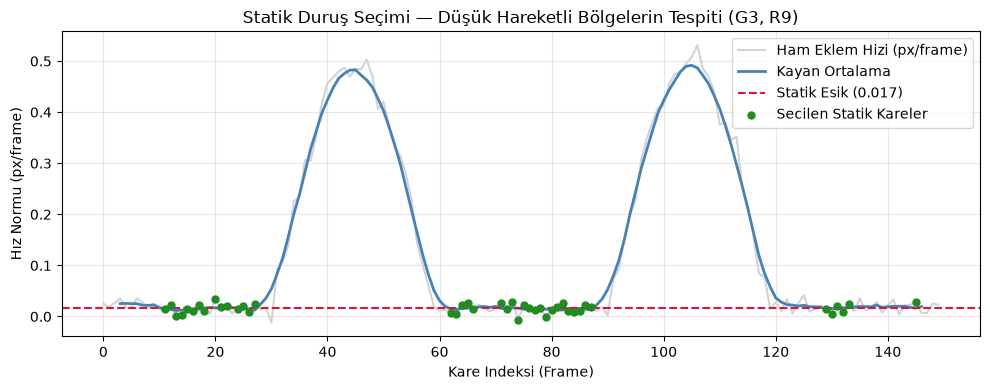

In [3]:
# Secilen Statik Bolgelerin Gorsellestirilmesi
plt.figure(figsize=(10, 4), dpi=100)
plt.plot(time_frames, velocity, label='Ham Eklem Hizi (px/frame)', color='lightgray')
plt.plot(np.arange(3, 3 + len(rolling_val)), rolling_val, label='Kayan Ortalama', color='steelblue', lw=2)
plt.axhline(thr, color='crimson', linestyle='--', label=f'Statik Esik ({thr:.3f})')
plt.scatter(static_idx, velocity[static_idx], color='forestgreen', s=25, label='Secilen Statik Kareler', zorder=5)
plt.title('Statik Duruş Seçimi — Düşük Hareketli Bölgelerin Tespiti (G3, R9)')
plt.xlabel('Kare Indeksi (Frame)')
plt.ylabel('Hız Normu (px/frame)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
